# Hackathon – Dataset C (COVID vaccine) · Notebook 06 of 09
## Repeated cross-validation and turning probabilities into decisions

**Module:** 7PAM2002 – University of Hertfordshire · **GitHub:** `<add link>` · **Colab:** `<add link>` · **Author of this notebook:** `<name>`

**Goal of the project:** predict which residents will accept a COVID vaccine and decide who to post a dose to so that the town's **total
cost (vaccines + hospitalisations)** is as small as possible.

<details><summary><b>The nine notebooks (run them in this order)</b></summary>

| # | Notebook | Content |
|---|---|---|
| 01 | `01_Problem_Framing_and_Cost_Metric.ipynb` | Problem framing and the task-specific cost metric |
| 02 | `02_EDA_Data_Quality.ipynb` | EDA part 1 – overview, target, missing values, data quality, train/test shift |
| 03 | `03_EDA_Feature_Relationships.ipynb` | EDA part 2 – distributions, associations, interactions, cost drivers |
| 04 | `04_Preprocessing.ipynb` | Pre-processing – cleaning, feature engineering, comparing four options |
| 05 | `05_Model_Tuning.ipynb` | Modelling – six model families and hyper-parameter tuning |
| 06 | `06_Cross_Validation_and_Decision_Strategy.ipynb` | Repeated cross-validation and turning probabilities into decisions |
| 07 | `07_Holdout_Evaluation_and_Robustness.ipynb` | Unseen hold-out evaluation, bootstrap uncertainty, robustness to assumptions |
| 08 | `08_Final_Selection_and_Submission.ipynb` | Final model selection and the five ranked submission files |
| 09 | `09_Explainable_AI_and_Conclusions.ipynb` | Explainable AI (SHAP, odds ratios, permutation importance) and conclusions |

Shared code (data loading, cost metric, cleaning, pipelines, models, evaluation helpers) lives in **`hackathon_utils.py`** so every notebook uses
exactly the same definitions. Results are passed from one notebook to the next through the **`artifacts/`** folder.
</details>


In [1]:
# ---- Set-up: run from the repository folder locally, or in Google Colab ----
import sys, os, subprocess, importlib, importlib.util
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/<your-organisation>/<your-repository>.git'   # <- set this once for Colab

if IN_COLAB and not Path('hackathon_utils.py').exists():
    subprocess.run(['git', 'clone', '-q', REPO_URL, 'repo'], check=True)   # get code, data and artifacts
    os.chdir('repo')

for pkg in ['xgboost', 'lightgbm', 'catboost', 'shap']:                    # CatBoost is not pre-installed on Colab
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from hackathon_utils import *            # shared data, cost metric, pipelines, models and helpers
print('train:', train_raw.shape, '| test:', test_raw.shape, '| scikit-learn', sklearn.__version__)

train: (4756, 31) | test: (4749, 30) | scikit-learn 1.6.1


In [2]:
from sklearn.calibration import calibration_curve

In [3]:
BEST_PREP = load_json('best_prep.json')          # notebook 04
TUNED_PARAMS = load_json('tuned_params.json')    # notebook 05
TUNED = build_tuned_models(BEST_PREP, TUNED_PARAMS)
print(list(TUNED))

['Baseline: prior only', 'Logistic Regression', 'Random Forest', 'Random Forest + isotonic', 'XGBoost', 'LightGBM', 'CatBoost', 'Ensemble (LR+XGB+LGBM+Cat)']


## 5.3 Repeated cross-validation of all tuned models (development set)
Each model is trained 10 times (5 folds × 2 repeats) and scored on the left-out fold with the task metric under the three decision strategies.

In [4]:
t0 = time.time()
cv_folds, OOF = [], {}
for name in MODEL_ORDER:
    f, oof = cv_evaluate(TUNED[name], X_dev, y_dev, name=name)
    cv_folds.append(f); OOF[name] = oof
    print(f'{name:30s} {time.time() - t0:5.0f}s')
cv_folds = pd.concat(cv_folds, ignore_index=True)
cv_table = summarise(cv_folds).reindex(MODEL_ORDER)
cv_table

# ---- Save for the next notebooks ----
cv_folds.to_csv(ART_DIR / 'cv_folds.csv', index=False)
pd.DataFrame(OOF, index=X_dev.index).to_csv(ART_DIR / 'oof_probs_dev.csv')

Baseline: prior only               0s
Logistic Regression               12s
Random Forest                     22s
Random Forest + isotonic          62s
XGBoost                           63s
LightGBM                          65s
CatBoost                          94s
Ensemble (LR+XGB+LGBM+Cat)       139s


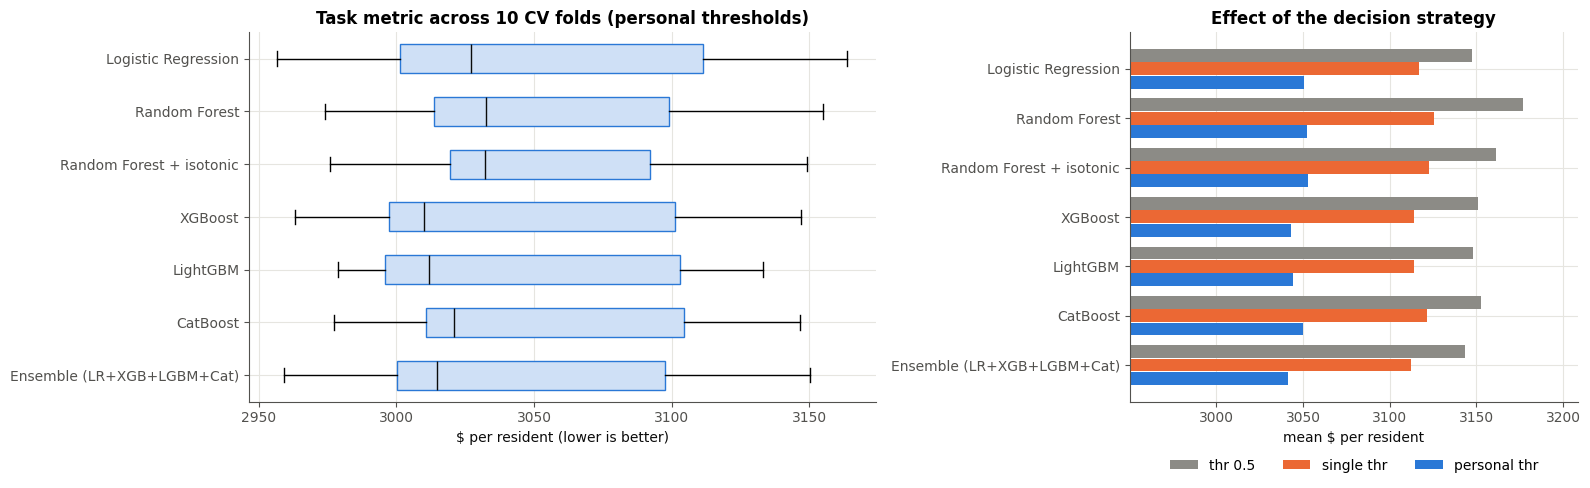

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [1.4, 1]})
models_no_base = [m for m in MODEL_ORDER if not m.startswith('Baseline')]
data = [cv_folds.loc[cv_folds['model'] == m, '$/resident [personal thr]'] for m in models_no_base]
try:   # matplotlib >= 3.10
    bp = axes[0].boxplot(data, orientation='horizontal', patch_artist=True, widths=0.55, medianprops={'color': INK})
except TypeError:
    bp = axes[0].boxplot(data, vert=False, patch_artist=True, widths=0.55, medianprops={'color': INK})
for patch in bp['boxes']:
    patch.set_facecolor('#cfe0f6'); patch.set_edgecolor(BLUE)
axes[0].set_yticks(range(1, len(models_no_base) + 1), models_no_base)
axes[0].set_xlabel('$ per resident (lower is better)'); axes[0].set_title('Task metric across 10 CV folds (personal thresholds)')

strat = cv_folds[cv_folds['model'].isin(models_no_base)].groupby('model')[[f'$/resident [{s}]' for s in STRATEGIES]].mean()
strat = strat.reindex(models_no_base)
x = np.arange(len(strat))
for i, (s, col) in enumerate(zip(STRATEGIES, [GREY, ORANGE, BLUE])):
    axes[1].barh(x + (i - 1) * 0.27, strat[f'$/resident [{s}]'], height=0.26, color=col, label=s)
axes[1].set_yticks(x, strat.index); axes[1].set_xlim(strat.values.min() * 0.97, strat.values.max() * 1.01)
axes[1].set_xlabel('mean $ per resident'); axes[1].set_title('Effect of the decision strategy')
axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3)
axes[1].invert_yaxis(); axes[0].invert_yaxis()
plt.tight_layout(); savefig('05_cv_models'); plt.show()

**What the cross-validation tells us**
* All tuned models are within ≈\$10 per resident (≈0.3 %) of each other, while the fold-to-fold standard deviation is ≈\$60: with ~3 800
  training rows the **information in the survey, not the algorithm, limits performance**. Boosted trees and the ensemble have the best log-loss and
  ROC-AUC, and the soft-voting ensemble has the lowest mean cost and a small spread.
* The **decision strategy matters more than the algorithm**: for every model, personal thresholds save ≈\$70–130 per resident compared with the naive
  0.5 threshold and ≈\$70 compared with the best single threshold.
* Even the *prior-only* baseline (same acceptance probability for everybody) captures almost **half** of the achievable saving once it is combined with
  personal thresholds – simply by posting doses to the high-risk residents. The hospitalisation-risk model is as valuable as the acceptance model.
* Random forest probabilities are compressed towards the middle; isotonic calibration helps it at fixed thresholds, but it still trails the boosted models.

## 6. From probabilities to decisions
### 6.1 Is the theory right? Cost as a function of a single threshold

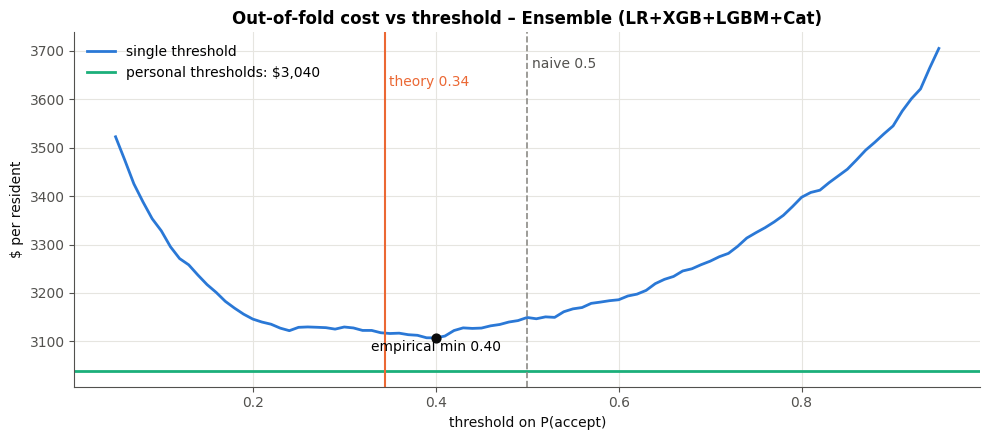

cost @0.5: 3149.4 | @theory: 3118.3 | personal: 3039.7


In [6]:
best_cv_model = cv_folds.groupby('model')['$/resident [personal thr]'].mean().drop('Baseline: prior only').idxmin()
first_rep_idx = np.arange(len(y_dev))                                  # OOF of first repeat covers every dev row once
p_oof = OOF[best_cv_model]
thresholds = np.linspace(0.05, 0.95, 91)
curve = [cost_per_person(y_dev, (p_oof >= t).astype(int), X_dev) for t in thresholds]
personal_cost = cost_per_person(y_dev, decide(p_oof, X_dev, 'personal thr'), X_dev)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(thresholds, curve, color=BLUE, lw=2, label='single threshold')
ax.axhline(personal_cost, color=AQUA, lw=2, ls='-', label=f'personal thresholds: ${personal_cost:,.0f}')
ax.axvline(0.5, color=GREY, ls='--', lw=1.2); ax.text(0.505, max(curve) * 0.995, 'naive 0.5', color=INK2, va='top')
t_star = MAIN.global_threshold()
ax.axvline(t_star, color=ORANGE, lw=1.5); ax.text(t_star + 0.005, max(curve) * 0.985, f'theory {t_star:.2f}', color=ORANGE, va='top')
t_emp = thresholds[int(np.argmin(curve))]
ax.scatter([t_emp], [min(curve)], color=INK, zorder=5, s=40); ax.text(t_emp, min(curve) - 4, f'empirical min {t_emp:.2f}', ha='center', va='top')
ax.set_xlabel('threshold on P(accept)'); ax.set_ylabel('$ per resident'); ax.legend(loc='upper left')
ax.set_title(f'Out-of-fold cost vs threshold – {best_cv_model}')
plt.tight_layout(); savefig('06_threshold_curve'); plt.show()
print(f'cost @0.5: {cost_per_person(y_dev, (p_oof >= 0.5).astype(int), X_dev):.1f} | @theory: '
      f'{cost_per_person(y_dev, (p_oof >= t_star).astype(int), X_dev):.1f} | personal: {personal_cost:.1f}')

The empirical minimum of the single-threshold curve sits very close to the theoretical value derived in Section 2 (≈0.35), confirming the
derivation, and the **personal-threshold rule beats every single threshold** – it is the strategy we use by default.

### 6.2 Calibration – are the probabilities trustworthy?
Personal thresholds only work if "70 %" really means 70 %. Reliability curves on out-of-fold predictions:

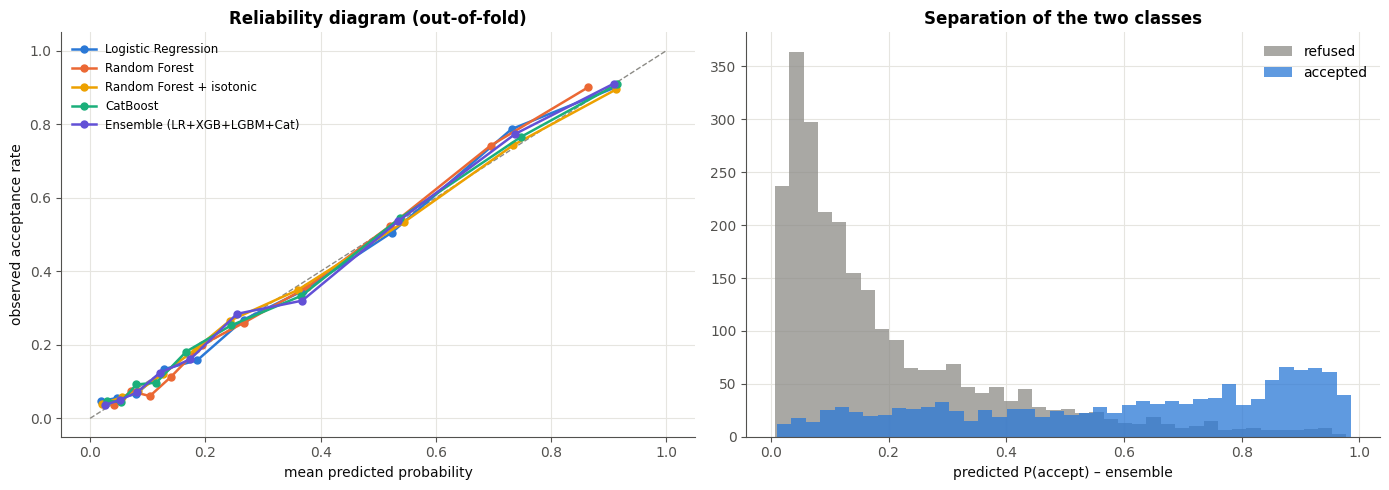

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot([0, 1], [0, 1], color=GREY, ls='--', lw=1)
for name, col in zip(['Logistic Regression', 'Random Forest', 'Random Forest + isotonic', 'CatBoost',
                      'Ensemble (LR+XGB+LGBM+Cat)'], [BLUE, ORANGE, YELLOW, AQUA, VIOLET]):
    frac, mean_p = calibration_curve(y_dev, OOF[name], n_bins=10, strategy='quantile')
    axes[0].plot(mean_p, frac, marker='o', ms=5, lw=1.8, color=col, label=name)
axes[0].set_xlabel('mean predicted probability'); axes[0].set_ylabel('observed acceptance rate')
axes[0].set_title('Reliability diagram (out-of-fold)'); axes[0].legend(fontsize=8.5)

ens = OOF['Ensemble (LR+XGB+LGBM+Cat)']
axes[1].hist(ens[y_dev.to_numpy() == 0], bins=40, alpha=0.75, color=GREY, label='refused')
axes[1].hist(ens[y_dev.to_numpy() == 1], bins=40, alpha=0.75, color=BLUE, label='accepted')
axes[1].set_xlabel('predicted P(accept) – ensemble'); axes[1].set_title('Separation of the two classes'); axes[1].legend()
plt.tight_layout(); savefig('06_calibration'); plt.show()

### 6.3 Decision map – who gets a vaccine posted?

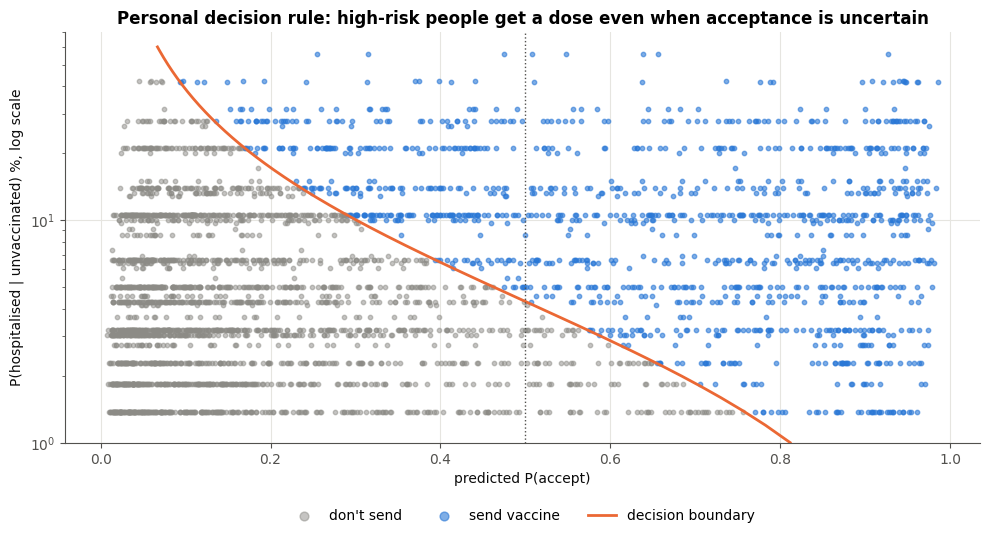

In [8]:
pp = MAIN.p_unvacc(X_dev)
send = decide(ens, X_dev, 'personal thr')
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(ens[send == 0], pp[send == 0] * 100, s=10, color=GREY, alpha=0.5, label="don't send")
ax.scatter(ens[send == 1], pp[send == 1] * 100, s=10, color=BLUE, alpha=0.6, label='send vaccine')
grid = np.linspace(0.01, 0.6, 300)
ax.plot(VACCINE_COST / (VACCINE_COST + HOSP_COST * MAIN.ve * grid), grid * 100, color=ORANGE, lw=2, label='decision boundary')
ax.axvline(0.5, color=INK2, ls=':', lw=1)
ax.set_yscale('log'); ax.set_xlabel('predicted P(accept)'); ax.set_ylabel('P(hospitalised | unvaccinated) %, log scale')
ax.set_ylim(1, 70)
ax.set_title('Personal decision rule: high-risk people get a dose even when acceptance is uncertain')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3, markerscale=2)
plt.tight_layout(); savefig('06_decision_map'); plt.show()

**Next:** notebook 07 checks every model once on the untouched hold-out set and tests robustness to the hospitalisation assumptions.